# Profiling a model during backpropagation

`profile` profiles a few warmed-up training steps. Every event gets a `launcher_id` pointing at
what launched it, so `aten::mm -> cudaLaunchKernel -> kernel` is a chain of links. Module hooks
wrap each module's work in `forward::<module>` and `backward::<module>` scopes, and a kernel
belongs to the nearest scope up its chain, or to `<unattributed>` if there is none.

1. Setup and profile
2. The report: one timeline per step
3. Kernels and their modules
4. Appendix: what each id is, and one kernel's launch chain

### What `profile` does

`profile` runs on a GPU worker: a plain warmup loop, then a measured loop, both over `profiling.util.training_step`. It trains the model it is passed, which decides whether it is compiled, with the optimizer and seed of the `TrainingParameters` it is passed. Two things are profile's own: `batch_size`, and the learning rate, which stays at `optimizer_parameters.lr` because profile runs no lr schedule.

1. Build the model, the optimizer and random tokens from the seed.
2. Run `warmup_steps` plain steps, then synchronize.
3. Run `profile_steps` many steps, each under the instruments `profile`'s switches turn on, and each ending in a synchronize. Both loops run forward and loss under `autocast`. Each phase of the step is wrapped in `util.phase`, which labels it with `record_function` and times it between synchronizes, so it shows up by name: `train::zero_grad`, `train::forward`, `train::loss`, `train::backward`, `train::optimizer_step`.
4. Return each step's readings (profiler `events`, memory peaks, allocator `snapshot`, `step_ms` and `wall_clock_phase_times`) under `steps`, the GPU's `device_vram`, the `size_estimation` of the model and the optimizer state, `step_flops`, and what it ran with.

`profile` takes one keyword switch per instrument: `kernel_events`, `module_scopes`, `peak` (peak allocated and reserved per step) and `trace` (each step's allocator trace, behind the memory plot). Phase times are always recorded. `capture_profiler_events` and `capture_memory`, in `profile_events.py`, are the context managers behind `kernel_events` and `peak`/`trace`; each does nothing when its switch is off.

**`record_function(name)`** adds a `user_annotation` event with that name. It is a label we add, not an operation PyTorch ran. Anything that starts and ends inside its time span becomes its child, so parent and child are decided by timestamps.

**`module_scopes(model)`** does the same per module: `forward::<module>` around each module's forward call, and `backward::<module>` around the backward work it owns. Later, a kernel is assigned to the module whose scope contains its launch.

A typical start of the events, in order, with start and end times in microseconds (illustrative values; the ids are from a real capture). `device_type` says where an event executed, CPU or GPU. Each indented row is a child of the row above it that is one level less indented. Annotations are ours, the rest is PyTorch:

```
                                       device_type      activity_type                     correlation_id  linked_correlation_id  start   end
train::zero_grad                       DeviceType.CPU   user_annotation            1 (frontend, PyTorch)                      0      0    40
  Optimizer.zero_grad#AdamW.zero_grad  DeviceType.CPU   user_annotation (PyTorch)  2 (frontend, PyTorch)                      0      5    35
train::forward                         DeviceType.CPU   user_annotation            3 (frontend, PyTorch)                      0     40  4200
  forward::model                       DeviceType.CPU   user_annotation            4 (frontend, PyTorch)                      0     45  4190
    forward::model.embedding           DeviceType.CPU   user_annotation            5 (frontend, PyTorch)                      0     50   300
      aten::index                      DeviceType.CPU   cpu_op                     6 (frontend, PyTorch)                      0     60   290
        cudaLaunchKernel               DeviceType.CPU   cuda_runtime                 11 (backend, CUPTI)  6 (frontend, PyTorch)    100   120
          vectorized_gather_kernel     DeviceType.CUDA  kernel (on the GPU)          11 (backend, CUPTI)  6 (frontend, PyTorch)    130   142
```

**Linking.** Parent and child among CPU events come from the timestamps, as above. A GPU event has no CPU parent in the trace, so `link_events` finds its launcher with correlation ids.

**CUDA** is NVIDIA's platform for running programs on its GPUs. It has a CPU side and a GPU side:

- On the CPU, the CUDA runtime library (`cuda_runtime` events, e.g. `cudaLaunchKernel`, `cudaMemcpyAsync`) and the lower-level driver it calls into (`cuda_driver`). These are ordinary CPU function calls that queue work for the GPU and return immediately.
- On the GPU, the work that was queued: `kernel`, `gpu_memcpy`, `gpu_memset`.

The `correlation_id` column holds ids from two separate namespaces, and the same number can appear in both. The boundary is who recorded the event, not CPU versus GPU:

- **Frontend:** events PyTorch's own profiler records for the operations your Python code calls: `cpu_op` and `user_annotation`. PyTorch numbers them with its own counter (1 to 6 above).
- **Backend:** every event of the CUDA layer, recorded by CUPTI, NVIDIA's profiling library (the CUDA Profiling Tools Interface). That is both the CPU-side CUDA calls (`cuda_runtime`, `cuda_driver`) and the GPU work they launch (`kernel`, `gpu_memcpy`, `gpu_memset`). CUPTI numbers them with its own counter (11 above), and a kernel gets the same id as the call that launched it.

So `device_type` is not the namespace boundary. `cudaLaunchKernel` has `DeviceType.CPU` because it executes on the CPU, yet its `correlation_id` is a backend id. `DeviceType.CUDA` marks only the GPU-side events, so it is not a name for the whole backend namespace. The namespace follows `activity_type`.

`linked_correlation_id` crosses between them. On a launch call or GPU event it holds the frontend `correlation_id` of the op that issued the launch (6, `aten::index`).

`link_events` keeps one lookup per namespace, so an id is only ever compared with ids of its own kind:

1. A kernel's backend `correlation_id` is looked up among the launch calls, so it is matched to the `cuda_runtime` call that launched it (11).
2. The launch call's `linked_correlation_id` is looked up among the frontend ids, so the call is matched to the op that issued it (6).

Each match sets `launcher_id` to the matched event's row. Following `launcher_id` from the kernel gives `kernel -> cudaLaunchKernel -> aten::index -> forward::model.embedding -> ...`, which is how a kernel finds its module scope. If a match is missing or ambiguous, `launcher_id` stays empty and the kernel is unattributed. See "What each id is" in the appendix.

In [ ]:
import torch

from artifacts.core.artifact import Resources
from profiling.profile_events import (
    aggregate_kernels,
    display_steps,
    events_to_rows,
    launch_chain,
)
from profiling.step_report import build_report
from profiling.util import phase, run_profile


### The training step

`profiling.util.training_step` is one training step, in phases: zero the gradients, forward and loss
under `autocast`, backward, step the optimizer.

In [3]:
from artifacts.core.SGD.training import LRSchedule, OptimizerParameters, TrainingParameters
from models.transformer import Transformer

model = Transformer(  # models.transformerV2.Transformer is the Triton variant
    vocab_size=10000,
    d_model=512,
    d_ff=1344,
    sequence_length=512,
    num_layers=10,
    num_heads=16,
    rope_theta=10000,
    dtype="torch.float32",  # strings parsed in the worker container
)
# As a Pretraining leg declares them; profile uses the optimizer, its parameters and the seed.
training_parameters = TrainingParameters(
    total_steps=20000,
    batch_size=64,
    max_norm=1.0,
    lr_schedule=LRSchedule(max_learning_rate=3e-4, min_learning_rate=3e-5, warmup_iters=200, cosine_cycle_iters=5000),
    optimizer="torch.optim.AdamW",
    optimizer_parameters=OptimizerParameters(lr=3e-4, betas=(0.9, 0.95), weight_decay=0.1, eps=1e-8),
    seed=0,
)

In [4]:
# Requested as a leg's allocated_resources are: the launcher starts a run with these same options.
resources = Resources(gpu_type="A100")  # any Modal GPU type, e.g. "A10", "A100", "H100"
# module_scopes does not work under torch.compile: turn it off if the model definition compiles.
captured = run_profile(
    resources,
    model_declaration = model,
    training_parameters = training_parameters,
    batch_size=training_parameters.batch_size,  # or any other, to sweep it
    warmup_steps=5,
    profile_steps=2,
    autocast=torch.bfloat16,  # or None for full precision
    kernel_events=True,
    module_scopes=True,
    peak_memory=True,
    trace_memory=True,
)

✓ Initialized. View run at 
https://modal.com/apps/ocanphys/main/ap-H4zA64tz2WmOAumjfM26hf
⠋ Initializing...
⠸ Creating objects...objects...
├── ⠋
├── ⠋
⠦ Creating objects...
├── ⠸ Creating mount /Users/oguz/Projects/launchpad/benchmarking/util.py: 
│   Uploaded 0/1 missing files
├── ⠸ Creating mount PythonPackage:main, PythonPackage:profile_events: Uploaded 
│   1/2 missing files
└── ⠸ Creating mount PythonPackage:config, PythonPackage:system, 
    PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models: 
⠏ Creating objects...
├── ⠦ Creating mount /Users/oguz/Projects/launchpad/benchmarking/util.py: 
│   Uploaded 0/1 missing files
├── ⠦ Creating mount PythonPackage:main, PythonPackage:profile_events: Uploaded 
│   1/2 missing files
└── ⠦ Creating mount PythonPackage:config, PythonPackage:system, 
    PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models: 
⠹ Creating objects...
├── ⠏ Creating mount /Users/oguz/Projects/launchpad/benchmarking/util.py: 
│   

## The report

`build_report`, in `step_report.py`, turns the profile into one JSON-serializable dict: `run` (the GPU,
model, optimizer, capture parameters, precision, peak rate and step FLOPs) and `steps`, each step's
phases, memory, kernels and module groups on the step's own clock. `display_steps` plots only from it,
one timeline per step: kernels by phase and module, allocated and reserved memory, and the shaded phases,
with the step's wall time, FLOPs and MFU under the legend. Every FLOP number is an algorithmic estimate
from op shapes; `report["run"]["sources"]` says how each was obtained.

**Two kinds of allocated memory.**

- **Persistent:** lives for the whole run. For a transformer trained with AdamW and fp32 weights this is the weights, their gradients, and AdamW's two moment buffers (`exp_avg`, `exp_avg_sq`), so about 4 times the size of the model. The memory panel draws it as `persistent_memory`.
- **Activation:** transient. The forward pass saves intermediate tensors for backward, so allocated memory climbs through forward, peaks around the start of backward, and falls as backward frees them. In the memory panel it is the bump above the persistent level.

Reserved memory does not fall back with it: the caching allocator keeps the freed blocks, so reserved stays at the high-water mark.

In [5]:
# Everything the plots show, as JSON: the run (GPU, model, capture parameters) and every step by number.
report = build_report(captured)
# json.dump(report, open("report.json", "w")) saves it; display_steps(json.load(open("report.json"))) plots it back.
report["run"]

{'gpu': {'name': 'NVIDIA A100-SXM4-40GB',
  'spec_row': 'A100-40GB',
  'vram_bytes': 42429251584},
 'model': {'class': 'Transformer',
  'parameters': {'device': 'cuda',
   'vocab_size': 10000,
   'sequence_length': 512,
   'num_layers': 10,
   'd_model': 512,
   'd_ff': 1344,
   'num_heads': 16,
   'rope_theta': 10000,
   'dtype': 'torch.float32'},
  'size': {'parameters': 41380352, 'bytes': 165521408}},
 'optimizer': {'class': 'AdamW',
  'state_parameters': 82760797,
  'state_bytes': 331043188},
 'capture': {'batch_size': 64,
  'warmup_steps': 5,
  'profile_steps': 2,
  'autocast': 'torch.bfloat16',
  'kernel_events': True,
  'module_scopes': True,
  'peak': True,
  'trace': True},
 'precision': 'torch.bfloat16',
 'peak': {'dtype': 'bf16', 'flops_per_s': 312000000000000.0},
 'step_flops': 8157753507840,
 'sources': {'step_flops': "algorithmic estimate: the model declaration's step_flops, an analytic count of one forward and backward pass from the architecture's shapes",
  'kernel_flop

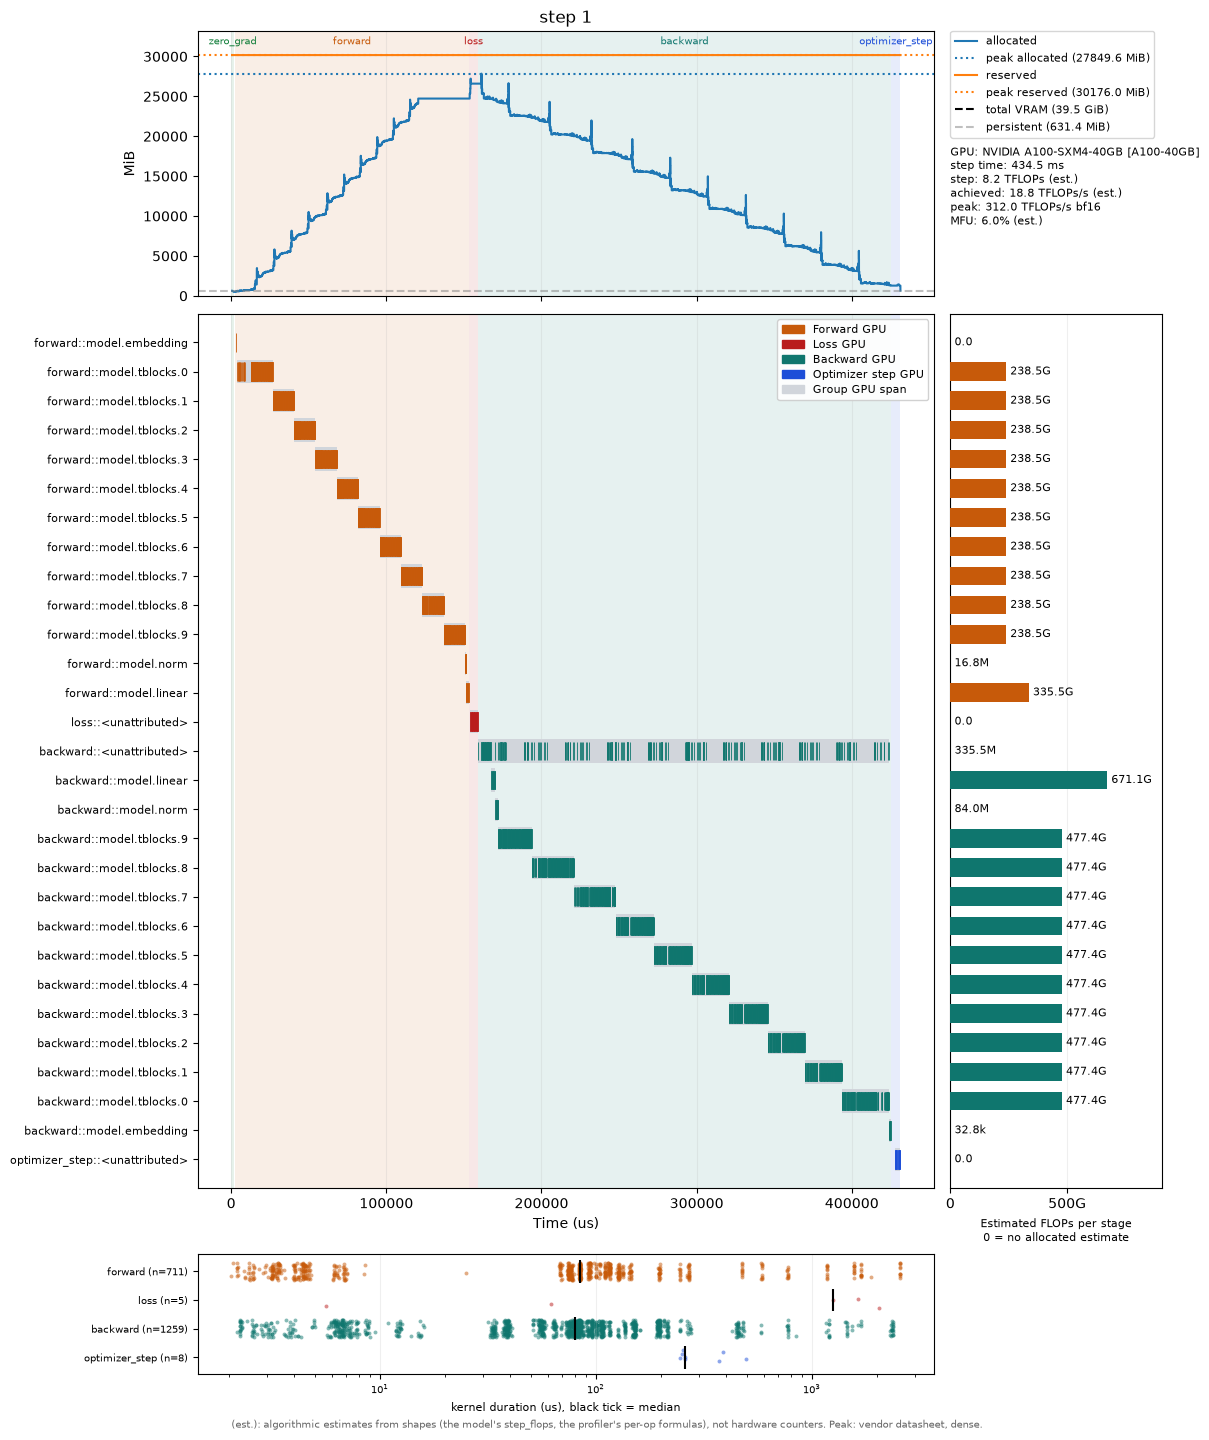

In [8]:
# Every step, stacked; pass steps=[...] to show some of them.
display_steps(report, steps=[1])

## Kernels and their modules

The tables behind the report, for one step. `groups` has one row per phase and module at `depth`
(3 is `model.tblocks.0`); `kernels` has one row per kernel with its module and GPU times.

In [9]:
step = max(captured["steps"])  # the report's key for it is str(step)
rows = events_to_rows(captured["steps"][step]["events"])
# Raises if a module-owned kernel never reaches the root scope.
groups, kernels, unattributed_kernels, flop_sources = aggregate_kernels(rows, depth=3)
print(f"{len(kernels)} kernels, {len(unattributed_kernels)} unattributed")
# gpu_time_us sums kernel durations; gpu_span_us also includes gaps between launches.
display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", "estimated_flops"]])

1983 kernels, 212 unattributed


kernel_count  gpu_time_us  gpu_span_us  \
phase          module_fqn                                                
forward        model.embedding             1       79.360       79.360   
               model.linear                2     1896.886     1898.902   
               model.norm                  8      451.678      462.366   
               model.tblocks.0            70    13661.880    22993.569   
               model.tblocks.1            70    13667.924    13770.708   
               model.tblocks.2            70    13687.576    13790.164   
               model.tblocks.3            70    13695.412    13806.451   
               model.tblocks.4            70    13675.220    13777.524   
               model.tblocks.5            70    13689.561    13791.988   
               model.tblocks.6            70    13689.627    13792.948   
               model.tblocks.7            70    13694.389    13796.595   
               model.tblocks.8            70    13697.107    13799.956   
               model.tblocks.9            70    13687.572    13787.732   
loss           <unattributed>              5     4995.364     5001.668   
backward       <unattributed>            199    17981.120   264999.304   
               model.embedding            10      150.014      800.027   
               model.linear                3     3107.631     3110.511   
               model.norm                 17     1352.443     1483.928   
               model.tblocks.0           103    17459.580    30242.777   
               model.tblocks.1           103    17476.031    23807.228   
               model.tblocks.2           103    17485.149    23782.525   
               model.tblocks.3           103    17473.790    24870.774   
               model.tblocks.4           103    17492.006    23805.213   
               model.tblocks.5           103    17473.280    24093.083   
               model.tblocks.6           103    17470.335    24696.248   
               model.tblocks.7           103    18247.071    26578.765   
               model.tblocks.8           103    18562.711    27119.690   
               model.tblocks.9           103    18576.122    21669.993   
optimizer_step <unattributed>              8     2521.747     3408.846   

                                estimated_flops  
phase          module_fqn                        
forward        model.embedding     0.000000e+00  
               model.linear        3.355443e+11  
               model.norm          1.680998e+07  
               model.tblocks.0     2.385428e+11  
               model.tblocks.1     2.385428e+11  
               model.tblocks.2     2.385428e+11  
               model.tblocks.3     2.385428e+11  
               model.tblocks.4     2.385428e+11  
               model.tblocks.5     2.385428e+11  
               model.tblocks.6     2.385428e+11  
               model.tblocks.7     2.385428e+11  
               model.tblocks.8     2.385428e+11  
               model.tblocks.9     2.385428e+11  
loss           <unattributed>      0.000000e+00  
backward       <unattributed>      3.355443e+08  
               model.embedding     3.276800e+04  
               model.linear        6.710886e+11  
               model.norm          8.395162e+07  
               model.tblocks.0     4.774210e+11  
               model.tblocks.1     4.774210e+11  
               model.tblocks.2     4.774210e+11  
               model.tblocks.3     4.774210e+11  
               model.tblocks.4     4.774210e+11  
               model.tblocks.5     4.774210e+11  
               model.tblocks.6     4.774210e+11  
               model.tblocks.7     4.774210e+11  
               model.tblocks.8     4.774210e+11  
               model.tblocks.9     4.774210e+11  
optimizer_step <unattributed>      0.000000e+00

In [10]:
# Unattributed kernels show module_fqn "<unattributed>".
display(kernels[["name", "phase", "module_fqn", "owner_fqn", "gpu_start_us", "duration_us"]])

,name,phase,module_fqn,owner_fqn,gpu_start_us,duration_us
index,,,,,,
14,"void at::native::vectorized_gather_kernel<16, ...",forward,model.embedding,model.embedding,8385.027,79.360
6100,void at::native::vectorized_elementwise_kernel...,forward,model.linear,model.linear,156614.096,25.088
6101,ampere_bf16_s16816gemm_bf16_128x128_ldg8_f2f_s...,forward,model.linear,model.linear,156641.200,1871.798
6091,void at::native::vectorized_elementwise_kernel...,forward,model.norm,model.norm,156150.387,93.919
6092,"void at::native::reduce_kernel<512, 1, at::nat...",forward,model.norm,model.norm,156245.938,67.904
...,...,...,...,...,...,...
24969,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,434014.931,385.950
25284,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,435281.292,250.431
25289,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,435532.779,259.327


## Appendix

## What each id is

`correlation_id` is `FunctionEvent.id`, which `_parse_kineto_results` fills with
`kineto_event.correlation_id()`. What it counts depends on the kind of row:

| Row (`activity_type`) | `correlation_id` | `linked_correlation_id` | `external_id` |
| --- | --- | --- | --- |
| Frontend: op or `record_function` scope (`cpu_op`, `user_annotation`) | PyTorch's own counter | 0 | `correlation_id` |
| Launch call on the CPU (`cuda_runtime`, `cuda_driver`) | CUPTI's counter | the op's `correlation_id` | `linked_correlation_id` |
| GPU work (`kernel`, `gpu_memcpy`, `gpu_memset`) | CUPTI's counter, equal to its launch call's | the op's `correlation_id` | `linked_correlation_id` |
| GPU span of a scope (`gpu_user_annotation`) | its scope's `correlation_id` | 0 | `correlation_id` |
| Profiler overhead (`overhead`) | reuses the `correlation_id` of the op it interrupted | 0 | 0 |

Two counters share the `correlation_id` column, so every lookup by it is restricted to one kind of row:
in one capture `Optimizer.step`'s GPU span and an unrelated launch call were both 1912.
`external_id` holds no value of its own: `KinetoEvent::externalId()` returns
`linked_correlation_id` when there is one, else `correlation_id`.

In [ ]:
# One kernel's launch chain, CPU root -> CUDA launch -> kernel. Kernel ids are the report's.
kernel_id = report["steps"][str(step)]["kernels"]["id"][0]  # Change this to any kernel id in the report.
print("Module:", kernels.loc[kernel_id, "module_fqn"])
display(launch_chain(rows, kernel_id, format=True))  # format=False for the raw rows